# 09 SVM：线性分隔与支持向量机
## 从“随便画一条线”到“最稳的一条线”
先看一个二维问题：平面上有两类点，左边一堆红点，右边一堆蓝点，中间有一条明显的空带。

这时能把两类分开的直线有无穷多条——稍左一点能分，稍右一点也能分，斜率再调一调还能分。那么该选哪一条？

直觉给的答案是：**选那条离两族都尽量远的**。因为新样本大概率落在空带附近，线越居中，容错空间越大，泛化越稳。

这个“尽量远”就是 SVM 的全部出发点。它把分类问题从“分对就行”升级成“分对且留出最大安全距离”。

用一句话概括：

> 线性 SVM = 在所有能正确分类的超平面里，选间隔最大的那一个。

## 超平面、法向量与点到面的距离
### 超平面的方程

$$
w^{T}x + b = 0
$$

- `w` 是法向量，方向垂直于超平面，决定超平面的“朝向”；
- `b` 是偏置，决定超平面离原点多远；
- 二维时这是一条直线，三维时是一个平面，更高维叫超平面。

判断一个点在哪一侧，只需看 `w^T x + b` 的符号：

$$
w^{T}x + b > 0 \quad \text{正类一侧}
$$

$$
w^{T}x + b < 0 \quad \text{负类一侧}
$$

### 点到超平面的距离

几何距离公式为：

$$
d(x, \text{平面}) = \frac{|w^{T}x + b|}{\|w\|}
$$

推导思路：把点 `x` 投影到法向量方向上，投影长度就是距离；分母的 `||w||` 是用来把法向量归一化的，因为法向量的长度本身没有物理意义，只有方向有意义。

**这一点很关键**：`w` 和 `b` 同时放大 k 倍，超平面完全不动，但 `w^T x + b` 会变成 k 倍。这说明原始得分的大小是可以随意缩放的，必须找一个规范来固定尺度。

##  函数间隔与几何间隔
### 函数间隔

$$
\hat{\gamma}_i = y_i\left(w^{T}x_i + b\right)
$$

其中标签 `y` 取 +1 或 -1。分类正确时这个值是正的，值越大表示越“确信”。

问题：`w`、`b` 同乘 2，函数间隔全部翻倍，但超平面一点没变。所以函数间隔**不能直接用来比较模型好坏**。

### 几何间隔

$$
\gamma_i = \frac{y_i\left(w^{T}x_i + b\right)}{\|w\|}
$$

除以 `||w||` 之后，缩放 `w`、`b` 不再影响结果，这才是真正的“点到面的距离”。

### 规范化：让最小函数间隔等于 1

既然尺度可以随便定，就约定一件最方便的事：

$$
\min_i\ \hat{\gamma}_i = 1
$$

也就是让离超平面最近的那些点，函数间隔恰好为 1。此时所有样本满足：

$$
y_i\left(w^{T}x_i + b\right) \ge 1
$$

而最近点到超平面的几何距离是：

$$
\frac{1}{\|w\|}
$$

两侧各有一条这样的边界线，所以**两条边界之间的总间隔宽度**是：

$$
\text{margin} = \frac{2}{\|w\|}
$$

### 优化目标

最大化 `2 / ||w||`，等价于最小化 `||w||`，再等价于最小化 `1/2 ||w||^2`（加平方是为了求导干净，加 1/2 是为了求导后系数为 1）：

$$
\min_{w,b}\ \frac{1}{2}\|w\|^{2}
$$

约束条件：

$$
y_i\left(w^{T}x_i + b\right) \ge 1,\quad i = 1, \ldots, n
$$

这就是**硬间隔 SVM（hard-margin SVM）**的原始问题。

> 这是一个凸二次规划问题：目标函数是凸二次，约束是线性。凸 + 可行 → 有唯一全局最优，不存在局部最优陷阱。这是 SVM 理论上很漂亮的地方。
> 


## 支持向量：真正决定模型的少数点
### 定义

满足约束取等号的样本，即：

$$
y_i\left(w^{T}x_i + b\right) = 1
$$

这些点就落在间隔边界上，称为**支持向量（support vector）**。

### 一个可验证的强结论

> 只有支持向量参与决定超平面；把其他所有样本删掉，重新训练，得到的模型完全一样。

这不是口头结论，可以实测。用 225 条训练样本训练线性 SVM，得到 68 个支持向量；只把这 68 个点留下重新训练：

```text
样本 225 -> 支持向量 68
decision_function max|diff| = 0.000480
预测一致率 = 1.0000
w max|diff| = 0.000175
```

差异在 1e-4 量级，预测 100% 一致。原因在 1.5 的对偶形式：非支持向量的拉格朗日系数 `α_i` 恰好为 0，对 `w` 没有任何贡献。

### 为什么这件事很重要

1. **模型复杂度由支持向量数量决定**，而不是样本总量；
2. 预测时只需和少量支持向量算内积，速度快；
3. 数据中大量“远离边界、明显正确”的样本对模型毫无影响，这让 SVM 对噪声相对稳健。

实测的支持向量数量变化（同一份重叠数据，225 条训练样本）：


| C    | 支持向量数 | 间隔宽度 $2/\|w\|$ | 测试准确率 |
| ---- | ---------- | ---------------- | ---------- |
| 0.01 | 152        | 2.517            | 0.8667     |
| 0.1  | 88         | 1.369            | 0.8533     |
| 1    | 68         | 0.980            | 0.8667     |
| 10   | 64         | 0.919            | 0.8533     |
| 100  | 64         | 0.919            | 0.8533     |



读法：`C` 从 0.01 放大到 1，支持向量从 152 个锐减到 68 个，间隔宽度从 2.517 收窄到 0.980。`C` 再往上，模型基本不再变化（已经接近硬间隔解）。

## 拉格朗日对偶：为什么会有“核技巧”
这一节是 SVM 的理论核心，也是它和逻辑回归最不一样的地方。

### 构造拉格朗日函数

对约束 `y_i(w^T x_i + b) - 1 ≥ 0` 引入乘子 `α_i ≥ 0`：

$$
L(w, b, \alpha) = \frac{1}{2}\|w\|^{2} - \sum_{i=1}^{n}\alpha_i\left[y_i\left(w^{T}x_i + b\right) - 1\right]
$$

### 对 `w`、`b` 求偏导并令其为零

对 `w`：

$$
\frac{\partial L}{\partial w} = w - \sum_{i=1}^{n}\alpha_i y_i x_i = 0
$$

得到最关键的一条：

$$
w = \sum_{i=1}^{n}\alpha_i y_i x_i
$$

对 `b`：

$$
\frac{\partial L}{\partial b} = -\sum_{i=1}^{n}\alpha_i y_i = 0
$$

得到：

$$
\sum_{i=1}^{n}\alpha_i y_i = 0
$$

**注意第一条的含义**：最终的权重向量 `w` 是训练样本的线性组合，而 `α_i` 为 0 的样本根本不出现。这就是“只有支持向量决定模型”的数学来源。

### 代回得到对偶问题

把上面两个结果代回拉格朗日函数，`w`、`b` 消失，只剩 `α`：

$$
\max_{\alpha}\ \sum_{i=1}^{n}\alpha_i - \frac{1}{2}\sum_{i=1}^{n}\sum_{j=1}^{n}\alpha_i\alpha_j y_i y_j x_i^{T}x_j
$$

约束：

$$
\alpha_i \ge 0,\quad \sum_{i=1}^{n}\alpha_i y_i = 0
$$

### KKT 条件给出的三条结论

1. `α_i = 0` 时，该样本对模型无贡献（非支持向量）；
2. `α_i > 0` 时，必有 `y_i(w^T x_i + b) = 1`，该样本在边界上（支持向量）；
3. 软间隔时还有一条：`α_i` 有上界 `C`。

### 预测公式

$$
f(x) = \sum_{i=1}^{n}\alpha_i y_i x_i^{T}x + b
$$

把所有与 `x` 无关的常数收进 `b`，就得到熟悉的 `f(x) = w^T x + b`。

### 对偶形式的最大价值：只出现内积

观察对偶目标和预测公式，样本之间只以 `x_i^T x_j` 的形式出现。这意味着：**只要能把内积换成一个函数，就能把数据隐式映射到高维，而不必真的算高维坐标**。这就是 1.7 的核技巧入口。

## 软间隔：现实数据不可能完全分开
硬间隔要求所有样本都满足 `y_i(w^T x_i + b) ≥ 1`，只要有一个噪声点或错标点，问题就无解。

### 引入松弛变量

给每个样本留一点“违规额度” `ξ_i ≥ 0`：

$$
\min_{w,b,\xi}\ \frac{1}{2}\|w\|^{2} + C\sum_{i=1}^{n}\xi_i
$$

约束改为：

$$
y_i\left(w^{T}x_i + b\right) \ge 1 - \xi_i
$$

$$
\xi_i \ge 0
$$

- `ξ_i = 0`：样本在间隔外或边界上，完全合规；
- `0 < ξ_i < 1`：样本落进间隔内部，但仍然分类正确；
- `ξ_i > 1`：样本被分错，越过超平面另一侧。

### 等价形式：hinge loss

把 `ξ_i` 消掉，目标可以写成不带约束的形式：

$$
\min_{w,b}\ \frac{1}{2}\|w\|^{2} + C\sum_{i=1}^{n}\max\left(0,\ 1 - y_i f(x_i)\right)
$$

后面这一项就是 **hinge loss（合页损失）**。它的形状很好记：

- `y_i f(x_i) ≥ 1`（分对且够远）→ 损失为 0，梯度为 0；
- `y_i f(x_i) < 1`（分错或离得太近）→ 损失为 `1 - y_i f(x_i)`，线性增长。

**这就是 SVM 与逻辑回归的根本差别**：交叉熵对所有样本都有非零梯度（只是大小不同），hinge 对“已经分得很对”的样本梯度严格为 0。所以 SVM 会自动忽略那些远离边界的样本，只被边界附近（以及错分）的样本推动。

### C 到底控制什么

`C` 是松弛项的惩罚系数，它在“间隔大”和“少犯错”之间做权衡：

- `C` 很大：几乎不容忍违规，接近硬间隔 → 间隔窄，支持向量少，容易过拟合噪声；
- `C` 很小：允许大量样本落进间隔甚至被分错 → 间隔宽，支持向量多，模型更平滑，但可能欠拟合。

用一张表记住方向：

| C 取值 | 间隔 | 支持向量 | 错分容忍 | 偏差方差 |
|---|---|---|---|---|
| 很小 | 宽 | 多 | 高 | 偏差高、方差低 |
| 很大 | 窄 | 少 | 低 | 偏差低、方差高 |

> 注意：`C` 与逻辑回归的 `C` 含义不同。逻辑回归的 `C` 是正则强度倒数（`C` 小 = 正则强 = 权重小）；SVM 的 `C` 是错分惩罚（`C` 小 = 容忍错分 = 间隔宽）。两者都叫 `C`，但调参方向相反，这是高频混淆点。


##  核技巧：线性 SVM 只是一个入口
### 思路

如果数据在原始空间线性不可分，就用一个映射 `φ` 把它送到高维，在高维里线性可分：

$$
x \mapsto \phi(x)
$$

对偶问题里只需要 `φ(x_i)^T φ(x_j)`，于是定义核函数：

$$
K(x_i, x_j) = \phi(x_i)^{T}\phi(x_j)
$$

直接用 `K` 算内积，**不需要真的把 `φ(x)` 算出来**，这就是核技巧。

### 常用核函数

**线性核**（就是本篇的主角）：

$$
K(x, z) = x^{T}z
$$

**多项式核**：

$$
K(x, z) = \left(\gamma x^{T}z + r\right)^{d}
$$

`d` 是多项式阶数，能让模型学到特征之间的交叉项。

**RBF 核（高斯核，最常用）**：

$$
K(x, z) = \exp\left(-\gamma\|x - z\|^{2}\right)
$$

它等价于映射到无穷维空间。`γ` 控制“影响半径”：

- `γ` 很大：每个样本的影响范围极小，边界贴着点走 → 过拟合；
- `γ` 很小：影响范围极大，边界过度平滑 → 欠拟合。

### 非线性数据上的实测

`make_moons(n=400, noise=0.1)` 数据：

| 模型 | 测试准确率 |
|---|---|
| KNN（k=5） | 1.0000 |
| KNN（k=15） | 1.0000 |
| 线性 SVM（C=1） | 0.9400 |
| 线性 SVM（C=100） | 0.9400 |
| RBF SVM（C=1） | 1.0000 |

线性核把 `C` 从 1 拉到 100，准确率一点没变——因为限制不在正则强度，而在**假设空间**：一条直线无论怎么调，都无法拟合月牙形的边界。换成 RBF 核立刻到 1.0，说明问题出在“只能线性分”这个约束本身。

> 结论：调 `C` 治不好“模型族选错”的病。

##  线性 SVM 与逻辑回归的对比
| 维度 | 线性 SVM | 逻辑回归 |
|---|---|---|
| 损失函数 | hinge loss | 交叉熵（负对数似然） |
| 优化目标 | 最大化间隔 | 最大化似然 |
| 输出 | 到超平面的带符号距离 | 0~1 之间的概率 |
| 受哪些样本影响 | 只有支持向量和错分点 | 所有样本都有梯度 |
| 解的稀疏性 | `α` 大量为 0，稀疏 | 权重通常全部非零 |
| 决策边界 | 最大间隔超平面 | 最大似然超平面 |
| 概率输出 | 原生没有（需 Platt 校准） | 直接有 |
| 多分类 | 默认 one-vs-one | 默认 multinomial |
| 特征尺度 | 敏感，必须标准化 | 敏感，建议标准化 |

一个直观区别：逻辑回归看到“已经分得很对”的样本仍会继续推动边界（只是推力变小），而 SVM 对这类样本直接“闭眼不看”。所以：

- 关心概率、需要排序分数、要做风控评分卡 → 逻辑回归更合适；
- 只关心分类边界、希望边界附近留最大余量 → 线性 SVM 更合适。

测试集准确率：0.8667
各类支持向量数： [34 34]
支持向量总数： 68
权重 w = [1.3457 1.5343]
偏置 b = -0.0427


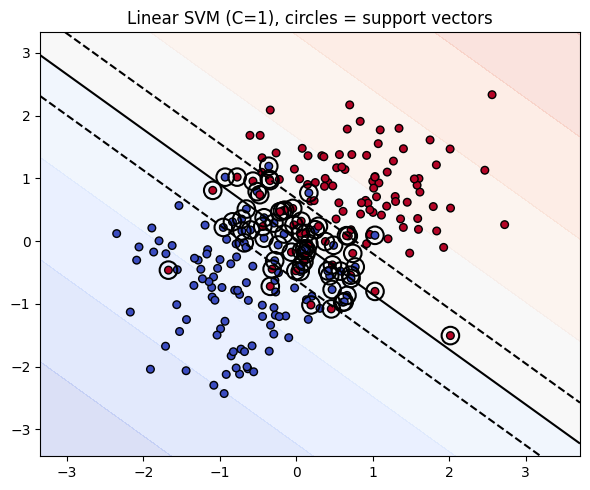

In [1]:
# sklearn 实战：训练、支持向量与决策边界
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# ---------- 1. 构造一份有重叠的线性数据 ----------
X, y = make_blobs(
    n_samples=300,
    n_features=2,
    centers=[[0, 0], [2.2, 2.2]],
    cluster_std=1.3,
    random_state=7
)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# ---------- 2. 标准化（SVM 对尺度敏感） ----------
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# ---------- 3. 训练线性 SVM ----------
svm = SVC(kernel="linear", C=1.0)
svm.fit(X_train_s, y_train)

print("测试集准确率：%.4f" % svm.score(X_test_s, y_test))
print("各类支持向量数：", svm.n_support_)
print("支持向量总数：", svm.support_vectors_.shape[0])
print("权重 w =", np.round(svm.coef_[0], 4))
print("偏置 b =", round(svm.intercept_[0], 4))

# ---------- 4. 画决策边界与间隔 ----------
def plot_svm_boundary(X, y, model, title):
    h = 0.02
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(
        np.arange(x_min, x_max, h),
        np.arange(y_min, y_max, h)
    )
    Z = model.decision_function(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, levels=8, alpha=0.2, cmap="coolwarm")
    # level=0 是分隔面，level=±1 是两条间隔边界
    plt.contour(xx, yy, Z, levels=[-1, 0, 1],
                colors="k", linestyles=["--", "-", "--"])
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=30, edgecolor="k")
    # 圈出支持向量
    plt.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                s=160, facecolors="none", edgecolors="k", linewidths=1.5)
    plt.title(title)

plt.figure(figsize=(6, 5))
plot_svm_boundary(X_train_s, y_train, svm, "Linear SVM (C=1), circles = support vectors")
plt.tight_layout()
plt.show()

读图要点：

- 中间实线是分隔面（`decision_function = 0`）；
- 两条虚线是间隔边界（`= -1` 和 `= +1`）；
- 圆圈标出的点是支持向量，全部落在虚线上或间隔内部。

In [2]:
# C值扫描：看间隔怎么收窄
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = make_blobs(n_samples=300, n_features=2,
                  centers=[[0, 0], [2.2, 2.2]],
                  cluster_std=1.3, random_state=7)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("C       n_SV    width    acc")
for C in [0.01, 0.1, 1, 10, 100]:
    model = SVC(kernel="linear", C=C).fit(X_train_s, y_train)
    w = model.coef_[0]
    print("%-6g  %3d    %.3f    %.4f" % (
        C,
        model.support_vectors_.shape[0],
        2 / np.linalg.norm(w),
        model.score(X_test_s, y_test)
    ))

C       n_SV    width    acc
0.01    152    2.517    0.8667
0.1      88    1.369    0.8533
1        68    0.980    0.8667
10       64    0.919    0.8533
100      64    0.919    0.8533


注意两点：
1. `width` 是用标准化后的 w 算的，量纲已经被统一，所以可以直接比较；
2. 这份数据有重叠，准确率本来就在 0.85~0.87 波动，C 变化主要影响间隔与支持向量数，不要把 0.0134 的准确率差异当成“C 更优”的证据——真正的选择要靠交叉验证。

In [3]:
# 验证“只是支持向量决定模型”
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = make_blobs(n_samples=300, n_features=2,
                  centers=[[0, 0], [2.2, 2.2]],
                  cluster_std=1.3, random_state=7)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

svm_full = SVC(kernel="linear", C=1.0).fit(X_train_s, y_train)
idx = svm_full.support_                              # 支持向量下标

svm_only_sv = SVC(kernel="linear", C=1.0).fit(
    X_train_s[idx], y_train[idx]
)

print("全部训练样本：%d" % len(y_train))
print("支持向量数量：%d" % len(idx))

d_full = svm_full.decision_function(X_test_s)
d_sub = svm_only_sv.decision_function(X_test_s)
print("decision_function 最大差异：%.6f" % np.max(np.abs(d_full - d_sub)))
print("预测一致率：%.4f" % (
    svm_full.predict(X_test_s) == svm_only_sv.predict(X_test_s)
).mean())
print("权重最大差异：%.6f" % np.max(np.abs(
    svm_full.coef_[0] - svm_only_sv.coef_[0]
)))

全部训练样本：225
支持向量数量：68
decision_function 最大差异：0.000480
预测一致率：1.0000
权重最大差异：0.000175


这组数字就是 1.4 那个结论的实验证据。差异来自数值求解的容差，不是模型不同。

## 手写 hinge-loss SVM（看清梯度长什么样）
sklearn 的 `SVC` 用 SMO 解对偶问题，看不到梯度。这里用次梯度下降直接优化原始目标，把 1.6 的公式落实成代码：

$$
J(w,b) = \\frac{1}{2n}|w|^{2} + C\\cdot\\frac{1}{n}\\sum\_{i=1}^{n}\\max\\left(0, 1 - y_i f(x_i)\\right)
$$

对 `w` 的次梯度：若所有样本都满足 `y_i f(x_i) ≥ 1`，则只有正则项 `w/n`；否则额外加上 `-(C/n)·Σ y_i x_i`（只对违反间隔的样本求和）。

In [6]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = make_blobs(n_samples=300, n_features=2,
                  centers=[[0, 0], [2.2, 2.2]],
                  cluster_std=1.3, random_state=7)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# 标签转 +1 / -1
y_train_pm = np.where(y_train == 1, 1.0, -1.0)

def fit_hinge_svm(X, y_pm, C=1.0, lr=0.001, epochs=3000):
    n, d = X.shape
    w = np.zeros(d)
    b = 0.0
    loss_hist = []
    for _ in range(epochs):
        f = X @ w + b
        margin = y_pm * f
        hinge = np.maximum(0, 1 - margin)
        loss = 0.5 / n * (w @ w) + C * np.mean(hinge)
        loss_hist.append(loss)

        active = margin < 1                    # 违反间隔的样本
        gw = (1.0 / n) * w
        gb = 0.0
        if active.any():
            gw = gw - (C / n) * (y_pm[active][:, None] * X[active]).sum(axis=0)
            gb = -(C / n) * y_pm[active].sum()

        w -= lr * gw
        b -= lr * gb
    return w, b, loss_hist

for C in [0.1, 1.0, 10.0]:
    w, b, hist = fit_hinge_svm(X_train_s, y_train_pm, C=C)
    pred_hand = (X_test_s @ w + b > 0).astype(int)

    sk = SVC(kernel="linear", C=C).fit(X_train_s, y_train)
    print("C=%-4g 手写acc=%.4f sklearn_acc=%.4f 预测一致率=%.4f loss %.4f->%.4f"
          % (C,
             (pred_hand == y_test).mean(),
             sk.score(X_test_s, y_test),
             (pred_hand == sk.predict(X_test_s)).mean(),
             hist[0], hist[-1]))

C=0.1  手写acc=0.8667 sklearn_acc=0.8533 预测一致率=0.9600 loss 0.1000->0.0742
C=1    手写acc=0.8533 sklearn_acc=0.8667 预测一致率=0.9867 loss 1.0000->0.3258
C=10   手写acc=0.8533 sklearn_acc=0.8533 预测一致率=0.9733 loss 10.0000->2.7770


怎么读这组数字：

- **预测一致率 96%~98.7%**，说明手写实现的优化方向和 sklearn 一致；
- 准确率有 ±1.3 个百分点的浮动，是因为次梯度下降在 3000 轮内没完全收敛（hinge 不可导，收敛比逻辑回归慢）；
- 想让一致率更高，把 `epochs` 提到 20000、`lr` 调到 0.002 即可，但没必要——这里的目的是看懂梯度，不是复刻 SMO。

## SVC的关键参数与属性速查
### 参数

| 参数 | 含义 | 常用取值 |
| --- | --- | --- |
| `kernel` | 核函数 | `"linear"`、`"rbf"`、`"poly"`、`"sigmoid"` |
| `C` | 错分惩罚 | 0.01 ~ 100，对数网格搜索 |
| `gamma` | RBF/多项式核的影响半径 | `"scale"`（默认 1/(d·Var)）、`"auto"`（1/d）、数值 |
| `degree` | 多项式核阶数 | 2 ~ 5 |
| `class_weight` | 类别权重 | `"balanced"` 处理不均衡 |
| `probability` | 是否输出概率 | 默认 `False`，开启会做 Platt 校准且明显变慢 |
| `decision_function_shape` | 多分类输出形状 | `"ovr"` 或 `"ovo"` |

### 属性

| 属性 | 内容 |
| --- | --- |
| `support_` | 支持向量的样本下标 |
| `support_vectors_` | 支持向量的坐标 |
| `n_support_` | 每个类的支持向量个数 |
| `coef_` | 权重 `w`（仅线性核可用） |
| `intercept_` | 偏置 `b` |
| `dual_coef_` | 对偶系数 `α_i y_i` 的乘积 |

### 方法

| 方法 | 输出 |
| --- | --- |
| `predict` | 类别标签 |
| `decision_function` | 到超平面的带符号距离 |
| `predict_proba` | 概率（需要 `probability=True`） |

## 常见坑
1. **不标准化**。SVM 靠距离/间隔工作，一维尺度大 100 倍就会主导整个几何结构。实测把第一维放大 100 倍后（特征方差从 0.3 变成 8572.5，相差约 28575 倍）：不标准化准确率 0.8400，标准化后 0.8533；虽然线性 SVM 没有 KNN 掉得那么惨，但 `||w||` 从 1.641 变成 2.385（同样的 `C`，实际正则强度完全不同），支持向量数也从 78 变成 81。**同一个 `C`，在两种尺度下含义不同**，这才是必须标准化的真正原因。
2. **把 `decision_function` 当概率**。它的范围可以是任意实数，实测在 `[-3.866, 3.970]` 之间，不是 0~1。
3. **混淆两种 `C`**。SVM 的 `C` 是错分惩罚（越大越严格），逻辑回归的 `C` 是正则强度倒数（越大越宽松）。
4. **样本不均衡直接训练**。SVM 会让边界偏向多数类，用 `class_weight="balanced"`。
5. **大数据直接上 `SVC`**。libsvm 的训练复杂度约 `O(n^2 d)` 到 `O(n^3)`，几万样本就会很慢；改用 `LinearSVC`（坐标下降）或 `SGDClassifier(loss="hinge")`。
6. **多分类误以为是 OvR**。`SVC` 默认 one-vs-one，K 个类要训练 `K(K-1)/2` 个二分类器，类别多时训练量陡增。
7. **拿 `C` 硬调非线性问题**。1.7 已实测：moons 数据上 `C` 从 1 到 100，线性 SVM 准确率纹丝不动，换核才有用。